# NLP Assignment 2: Apply Word2Vec to Downstream Tasks

In this assignment, you will perform two tasks using Word2Vec:
- Unsupervised PoS tagging using K-Means
- Unsupervised Extractive Summarisation

**We will randomly run 15 submissions. If any bug occurs during execution OR the results fall outside a reasonable reproducible range compared to the logged results, the submission will receive 0 mark for this assignment.**

## 0. Load pre-trained Glove embeddings

In this step, we load the pre-trained GloVe word embeddings from the text file specified by glove_path.
The function load_glove reads the file line by line and processes each entry by:
- Splitting each line into the token (word) and its corresponding embedding values;
- Converting the embedding values from strings to float32 arrays;
- Cleaning the token by removing non-breaking spaces and skipping tokens that contain whitespace or are empty;
- Optionally limiting the number of loaded lines through the max_lines parameter.

The final result is stored in the dictionary glove_vectors. Please download the model (glove.2024.wikigiga.100d.zip, 560MB) at https://nlp.stanford.edu/projects/glove/.

In [37]:
import numpy as np
from typing import Optional

def load_glove(path: str, dim: int = 100, max_lines: Optional[int] = None) -> dict:
    vectors = {}
    nb_space = u"\xa0"
    with open(path, "r", encoding="utf-8") as f:
        for i, line in enumerate(f):
            if max_lines is not None and i >= max_lines:
                break
            parts = line.strip().split()
            if len(parts) <= dim:
                continue
            tail = parts[-dim:]
            try:
                vec = np.array([float(x) for x in tail], dtype=np.float32)
            except ValueError:
                continue
            token = " ".join(parts[:-dim]).replace(nb_space, " ").strip()
            if " " in token or token == "":
                continue  
            vectors[token] = vec
    return vectors

glove_path = "./wiki_giga_2024_100_MFT20_vectors_seed_2024_alpha_0.75_eta_0.05.050_combined.txt" # Replace path_to_your_file with the path to the glove embedding.
glove_vectors = load_glove(glove_path)

print(f"GloVe Loaded. Vocab size: {len(glove_vectors):,}")

GloVe Loaded. Vocab size: 1,287,614


## 1. Apply Word2Vec to Unsupervised PoS Tagging.
In this step, we use word embeddings to perform unsupervised part-of-speech (PoS) tagging through clustering.
The key idea is that words with similar syntactic functions tend to appear in similar contexts and therefore have similar vector representations in the embedding space.

The process involves:
- Using pre-trained Word2Vec (or GloVe) embeddings to represent each word as a dense vector;
- Grouping words into clusters based on their embedding similarity using an unsupervised clustering algorithm (e.g. K-Means);
- Evaluating the quality of the induced clusters against gold PoS tags using information-theoretic metrics.
- Visualise the clustered embeddings.

In this task, we will use K-Means to group text from brown corpus.

### 1.1 Download the Brown Corpus.
We download the brown corpus from nltk to obtain the sentences and corresponding PoS tags. We use the first 500 instances for this task.

The number of unique PoS tags in this subset will be used as the number of clusters (k) in the later clustering step.

In [38]:
import nltk

nltk.download('brown')
nltk.download('universal_tagset')

from nltk.corpus import brown

tagged_sents = brown.tagged_sents(tagset='universal')[:500]
upos_tags = [t for sent in tagged_sents for (_, t) in sent]

### print(tagged_sents[:2])

# Calculate the number of PoS tags, which will be used as the k for clustering.
unique_upos = sorted(set(upos_tags))
print(f"PoS tag num: {len(unique_upos)}")
print("PoS list:", unique_upos)


[nltk_data] Downloading package brown to
[nltk_data]     /Users/aalimkalam/nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package universal_tagset to
[nltk_data]     /Users/aalimkalam/nltk_data...
[nltk_data]   Package universal_tagset is already up-to-date!


PoS tag num: 12
PoS list: ['.', 'ADJ', 'ADP', 'ADV', 'CONJ', 'DET', 'NOUN', 'NUM', 'PRON', 'PRT', 'VERB', 'X']


### 1.2 Build Token Embeddings and Gold Tags

In this step, we align the words in the Brown corpus with the pre-trained GloVe embeddings and extract the corresponding PoS tags.

The process involves:
- Collecting words from the tagged sentences and converting them to lowercase;
- Checking whether each word exists in the GloVe vocabulary;
-- If in-vocabulary, we store its embedding and gold PoS tag;
-- If out-of-vocabulary (OOV), we skip it;

The outputs include:
- token_embeddings: mapping from each unique in-vocabulary word to its embedding vector;
- vocab_words: list of unique in-vocabulary word types;
- input_tokens and gold_tags: word-level tokens and their corresponding PoS tags (for evaluation only);
- X contains the GloVe embeddings of unique word types with the shape (V, D), where V is the number of unique in-vocab word types and D is the embedding dimension.


In [39]:
import numpy as np
from typing import Dict, List, Tuple

def build_token_embeddings_and_gold_tags(
    tagged_sents: List[List[Tuple[str, str]]],
    glove_vectors: Dict[str, np.ndarray],
    lowercase: bool = True
):
    token_embeddings: Dict[str, np.ndarray] = {}
    input_tokens: List[str] = []
    gold_tags: List[str] = []

    total_tokens = 0
    iv_count = 0
    oov_count = 0

    for sent in tagged_sents:
        for w, tag in sent:
            total_tokens += 1
            w_proc = w.lower() if lowercase else w

            if w_proc in glove_vectors:
                iv_count += 1
                input_tokens.append(w_proc)
                gold_tags.append(tag)

                if w_proc not in token_embeddings:
                    token_embeddings[w_proc] = glove_vectors[w_proc]
            else:
                oov_count += 1

    vocab_words = list(token_embeddings.keys())
    if len(vocab_words) == 0:
        raise ValueError("Please check your data.")
    d = token_embeddings[vocab_words[0]].shape[0]
    X = np.vstack([token_embeddings[w] for w in vocab_words]).astype(np.float32)
    assert X.shape == (len(vocab_words), d)

    stats = {
        "total_tokens": total_tokens,
        "in_vocab_tokens": iv_count,
        "oov_tokens": oov_count,
        "oov_ratio": oov_count / max(total_tokens, 1),
        "vocab_size_unique_in_glove": len(vocab_words),
        "embedding_dim": d,
    }
    return token_embeddings, vocab_words, X, input_tokens, gold_tags, stats


token_embeddings, vocab_words, X, input_tokens, gold_tags, stats = build_token_embeddings_and_gold_tags(
    tagged_sents=tagged_sents,
    glove_vectors=glove_vectors,
    lowercase=True
)


print("Finish building")
print(f"- Total token num: {stats['total_tokens']}")
print(f"- In-vocab token num: {stats['in_vocab_tokens']}")
print(f"- OOV token num: {stats['oov_tokens']} ({stats['oov_ratio']:.2%})")
print(f"- In-vocab type num: {stats['vocab_size_unique_in_glove']}")



Finish building
- Total token num: 11711
- In-vocab token num: 11558
- OOV token num: 153 (1.31%)
- In-vocab type num: 2626


### 1.3 Cluster Word Embeddings with K-Means (Unsupervised PoS Induction)

In this step, we run **K-Means** on the (unique) word-type embeddings to induce PoS-like clusters.  
The intuition is that words with similar syntactic or semantic behaviour are close in the embedding space and therefore tend to fall into the same cluster.

#### Process
- L2-normalise all word vectors (row-wise) to stabilise distance comparisons;
- Initialise centroids with **k-means++** for better starting positions;
- Run multiple random restarts (`n_init` times), each using Lloyd’s algorithm up to `max_iter`;
- Select the run with the **lowest inertia** (tightest clusters);
- Store a **type-level** mapping `word2cluster` for downstream evaluation.

#### Inputs
- `X ∈ ℝ^{V×D}`: embedding matrix of unique in-vocab word types (same order as `vocab_words`);
- `vocab_words` (length = V): list of unique word types;
- `k`: number of clusters (here set to the number of UPOS tags);
- `n_init`, `max_iter`, `tol`: clustering hyperparameters;
- `random_state`: seed for reproducible initialisations.

#### Outputs (stored in the trained model)
- `labels_ ∈ {0,…,k−1}^V`: cluster ID for each word type;
- `centroids_ ∈ ℝ^{k×D}`: learned cluster centroids;
- `inertia_`: within-cluster sum of squared distances (lower is better);
- `n_iter_`: number of iterations used in the best run;
- `best_seed_`: random seed corresponding to the best run;
- `word2cluster: Dict[str, int]`: mapping from word type to cluster ID, later used to assign token-level labels.

Note: The `labels_` are cluster labels, not gold PoS tags. They are later used for evaluation against the gold labels (PoS tags) at the token level to compute evaluation metrics (e.g., Mutual Information, Normalised Mutual Information, V-measure, Variation of Information).


In [40]:
import numpy as np
from typing import List, Dict, Optional

class KMeansPOSTagger:
    """
    Minimal K-Means implementation for unsupervised PoS induction.
    - Uses L2 normalisation on input embeddings.
    - Uses k-means++ for centroid initialisation.
    - Runs multiple random restarts and keeps the best result.
    - Stores word2cluster mapping for evaluation.
    """

    def __init__(
        self,
        k: int,
        n_init: int = 10,
        max_iter: int = 100,
        tol: float = 1e-4,
        random_state: Optional[int] = None,
        init: str = "k-means++",
    ):
        """
        Parameters
        ----------
        k : int
            Number of clusters (here equal to the number of UPOS tags).
        n_init : int
            Number of random restarts. The best run (lowest inertia) is kept.
        max_iter : int
            Maximum number of iterations for Lloyd’s algorithm in each run.
        tol : float
            Convergence tolerance. If centroid shift or inertia improvement is smaller than this value, stop iterating.
        random_state : Optional[int]
            Seed for reproducibility. If None, uses random seed.
        init : str
            Initialisation method for centroids. 
            Supported: "k-means++" (default) or "random".
        """
        self.k = k
        self.n_init = n_init
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.init = init

        # Learned attributes (after clustering)
        self.vocab_: List[str] = [] # list of unique in-vocab word types
        self.labels_: Optional[np.ndarray] = None # cluster label per word type
        self.centroids_: Optional[np.ndarray] = None # learned centroid matrix [k, d]
        self.inertia_: Optional[float] = None # final inertia
        self.n_iter_: Optional[int] = None # iterations in the best run
        self.best_seed_: Optional[int] = None # random seed of best run
        self.word2cluster_: Dict[str, int] = {} # mapping word -> cluster ID

    @staticmethod
    def _l2norm_rows(X: np.ndarray, eps: float = 1e-12) -> np.ndarray:
        """
        L2-normalise each row of the embedding matrix X to unit length.
        This ensures all vectors have the same scale for clustering.
        """
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        return X / (norms + eps)

    @staticmethod
    def _kmeans_pp_init(X: np.ndarray, k: int, rng) -> np.ndarray:
        """
        Initialise centroids using k-means++:
        - Choose the first centroid randomly.
        - Choose each subsequent centroid with probability proportional to its squared distance to the nearest centroid.
        """
        n, d = X.shape
        centroids = np.empty((k, d), dtype=X.dtype)
        first = int(rng.integers(0, n))
        centroids[0] = X[first]
        closest_sq = np.full(n, np.inf, dtype=X.dtype)
        for i in range(1, k):
            dists = np.linalg.norm(X - centroids[i-1], axis=1) ** 2
            closest_sq = np.minimum(closest_sq, dists)
            probs = closest_sq / (closest_sq.sum() + 1e-12)
            idx = int(rng.choice(n, p=(probs / probs.sum())))
            centroids[i] = X[idx]
        return centroids

    @staticmethod
    def _assign(X: np.ndarray, C: np.ndarray) -> np.ndarray:
        """
        Assign each point in X to the nearest centroid in C.
        Distance metric: squared Euclidean distance.
        Returns
        -------
        labels : np.ndarray
            Shape (n,), cluster index for each data point.
        """
        x2 = (X**2).sum(axis=1, keepdims=True)
        c2 = (C**2).sum(axis=1, keepdims=True).T
        d2 = x2 + c2 - 2 * (X @ C.T)
        return d2.argmin(axis=1)

    @staticmethod
    def _update(X: np.ndarray, y: np.ndarray, k: int) -> np.ndarray:
        """
        Recompute cluster centroids:
        - For each cluster, take the mean of all assigned points.
        """
        d = X.shape[1]
        C = np.zeros((k, d), dtype=X.dtype)
        for i in range(k):
            m = (y == i)
            C[i] = X[m].mean(axis=0) if m.any() else X[np.random.randint(0, len(X))]
        return C

    @staticmethod
    def _inertia(X: np.ndarray, y: np.ndarray, C: np.ndarray) -> float:
        """
        Compute total within-cluster sum of squared distances (inertia).
        Lower inertia = tighter clusters.
        """
        D = X - C[y]
        return float((D**2).sum())

    def fit(self, X: np.ndarray, vocab_words: List[str]):
        """
        Run K-Means clustering on the embedding matrix.

        Steps:
        1. Use L2 normalisation on X.
        2. Run multiple random restarts (n_init times).
        3. For each run:
           - Initialise centroids (k-means++ or random)
           - Run Lloyd's algorithm until convergence or max_iter
           - Track best run with minimal inertia
        4. Save best clustering result and build word2cluster mapping.

        Parameters
        ----------
        X : np.ndarray
            Word embedding matrix of shape [V, D], where V is vocab size and D is embedding dim.
        vocab_words : List[str]
            List of word types corresponding to the rows in X.
        """
        assert len(vocab_words) == X.shape[0], "vocab length must match X rows"
        self.vocab_ = list(vocab_words)

        # L2 normalisation
        X_in = self._l2norm_rows(X)

        # Multiple restarts
        rng_base = np.random.default_rng(self.random_state)
        best = None

        for _ in range(self.n_init):
            seed = int(rng_base.integers(0, 2**31 - 1))
            rng = np.random.default_rng(seed)

            # Initialisation
            if self.init == "k-means++":
                C = self._kmeans_pp_init(X_in, self.k, rng)
            else:
                C = X_in[rng.choice(len(X_in), size=self.k, replace=False)].copy()

            # Iterations
            prev_inertia = None
            for it in range(self.max_iter):
                y = self._assign(X_in, C)
                C_new = self._update(X_in, y, self.k)
                inertia = self._inertia(X_in, y, C_new)
                shift = np.linalg.norm(C_new - C)
                C = C_new
                if prev_inertia is not None and abs(prev_inertia - inertia) < self.tol:
                    break
                if shift < self.tol:
                    break
                prev_inertia = inertia

            # Save run
            res = {"labels": y, "centroids": C, "inertia": inertia, "n_iter": it + 1, "seed": seed}
            if best is None or res["inertia"] < best["inertia"]:
                best = res

        # Save best result
        self.labels_ = best["labels"]
        self.centroids_ = best["centroids"]
        self.inertia_ = best["inertia"]
        self.n_iter_ = best["n_iter"]
        self.best_seed_ = best["seed"]
        self.word2cluster_ = {w: int(c) for w, c in zip(self.vocab_, self.labels_)}

        # Print logs
        print(" K-Means finished")
        print(f"Inertia: {self.inertia_:.4f}")
        print(f"Iterations: {self.n_iter_}")
        print(f"Best init seed: {self.best_seed_}")

        return self


# Run K-Means clustering
k = len(unique_upos)  # number of clusters = number of UPOS tags
tagger = KMeansPOSTagger(k=k, n_init=50, max_iter=200, random_state=42)
tagger.fit(X, vocab_words)
word2cluster = tagger.word2cluster_




 K-Means finished
Inertia: 1468.8541
Iterations: 39
Best init seed: 184566854


### 1.4 Evaluation: Cluster Quality vs. Gold PoS Tags (20%)

In this step, we evaluate how well the induced clusters align with the gold PoS tags from the corpus.  
We build a contingency matrix between cluster assignments and gold labels and compute several widely used information-theoretic evaluation metrics.

1. Map tokens to cluster IDs:  
   - Each token is assigned to the cluster of its corresponding word type.

2. Build contingency matrix:  
   - Rows correspond to predicted clusters;  
   - Columns correspond to gold PoS tags;  
   - Each cell counts how many tokens from a given cluster belong to each gold tag.

3. Compute evaluation metrics:
   - Mutual Information (MI): Measures how much information cluster assignments and gold labels share.  
   - Normalised Mutual Information (NMI): Normalises MI by the entropy of both cluster and tag distributions.  
   - Homogeneity: Measures whether each cluster contains only members of a single gold class.  
   - Completeness: Measures whether all members of a gold class are assigned to the same cluster.  
   - V-measure: Harmonic mean of Homogeneity and Completeness.  
   - Variation of Information (VI): Distance between cluster and gold distributions (lower is better).

In [41]:
import numpy as np
from typing import List, Tuple

def build_contingency(
    cluster_ids: List[int],
    gold_tags: List[str],
) -> Tuple[np.ndarray, List[int], List[str]]:
    """
    Build contingency matrix C[cluster, tag].
    Labels are automatically sorted internally.
    """
    clusters = sorted(list(set(cluster_ids)))
    tags = sorted(list(set(gold_tags)))
    C = np.zeros((len(clusters), len(tags)))

    cluster_to_row = {cluster:row for row, cluster in enumerate(clusters)}
    tag_to_column = {tag: column for column, tag in enumerate(tags)}

    for c, t in zip(cluster_ids, gold_tags):
        C[cluster_to_row[c], tag_to_column[t]] += 1
    

    return C, clusters, tags

def entropy(p: np.ndarray) -> float:
    """Compute Shannon entropy H(p)."""
    # Please complete your code here.
    H = -1 * np.sum((p * np.log2(p)))
    return float(H)

def mutual_information(C: np.ndarray) -> float:
    """Compute mutual information I(C;T)."""
    # Please complete your code here.
    probs_ij = C / C.sum()
    probs_i = probs_ij.sum(axis=1)
    probs_j = probs_ij.sum(axis=0)

    I = 0.0

    rs,cs = probs_ij.shape

    for i in range(rs):
        for j in range(cs):
            if probs_ij[i,j] > 0:
                I += probs_ij[i,j] * np.log2(probs_ij[i,j] / (probs_i[i] * probs_j[j]))

    return float(I)

def normalised_mutual_information(C: np.ndarray) -> float:
    """Compute normalised mutual information (NMI) with sqrt normalisation."""
    # Please complete your code here.
    N = C.sum()

    probs_k = C.sum(axis=1)/N
    probs_t = C.sum(axis=0)/N

    entropy_k = entropy(probs_k)
    entropy_t = entropy(probs_t)
    
    if entropy_k == 0.0 or entropy_t == 0.0:
        return 0.0

    NMI = mutual_information(C) / np.sqrt(entropy_k * entropy_t)
    return float(NMI)

def homogeneity(C: np.ndarray) -> float:
    """Compute homogeneity."""
    # Please complete your code here.
    N = C.sum()

    probs_t = C.sum(axis=0) / N
    entropy_t = entropy(probs_t)

    if entropy_t == 0: #perfect if all identical
        return 1.0 

    H = mutual_information(C) / entropy_t

    return float(H)

def completeness(C: np.ndarray) -> float:
    """Compute completeness."""
    # Please complete your code here.
    N = C.sum()

    probs_k = C.sum(axis=1) / N
    entropy_k = entropy(probs_k)

    if entropy_k == 0: #perfect if all in 1 cluster
        return 1.0 
    
    Comp = mutual_information(C) / entropy_k

    return float(Comp)

def v_measure(C: np.ndarray) -> float:
    """Compute V-measure."""
    # Please complete your code here.
    h = homogeneity(C)
    c = completeness(C)

    V = (2 * h * c) / (h + c)
    return float(V)

def variation_of_information(C: np.ndarray) -> float:
    """Compute Variation of Information (VI)."""
    # Please complete your code here.
    N = C.sum()

    probs_t = C.sum(axis=0) / N
    entropy_t = entropy(probs_t)

    probs_k = C.sum(axis=1) / N
    entropy_k = entropy(probs_k)

    VI = entropy_t + entropy_k - 2 * mutual_information(C)

    return float(VI)

# Map each token in the corpus to its cluster ID from KMeans
cluster_ids_for_tokens = [word2cluster[w] for w in input_tokens]

# Evaluate the PoS tagging performance
C, clusters, tags = build_contingency(cluster_ids_for_tokens, gold_tags)
I_score = mutual_information(C)
NMI_score = normalised_mutual_information(C)
H_score = homogeneity(C)
Cmp_score = completeness(C)
V_score = v_measure(C)
VI_score = variation_of_information(C)

print(f"Mutual Information (I): {I_score:.4f}")
print(f"Normalised Mutual Info (NMI): {NMI_score:.4f}")
print(f"Homogeneity: {H_score:.4f}")
print(f"Completeness: {Cmp_score:.4f}")
print(f"V-measure: {V_score:.4f}")
print(f"Variation of Information: {VI_score:.4f}")

Mutual Information (I): 0.6769
Normalised Mutual Info (NMI): 0.2378
Homogeneity: 0.2307
Completeness: 0.2452
V-measure: 0.2377
Variation of Information: 4.3407


### 1.5 Visualisation of Clustering Results with SVD

In this step, we use SVD to project the high-dimensional word embeddings into 2D space, and visualise the clustering.

In [ ]:
!pip install scikit-learn

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from collections import Counter

def plot_clusters_svd(
    X: np.ndarray,
    cluster_ids: np.ndarray,
    vocab: list,
    input_tokens: list,
    topn_per_cluster: int = 20,
    figsize: tuple = (10, 8),
    random_state: int = 42
):
    """
    Plot clustered embeddings after SVD dimensionality reduction.
    Each point is a word, colored by cluster ID.
    Only top N words per cluster are plotted based on token frequencies.

    Parameters
    ----------
    X : np.ndarray [V, D]
        Word embedding matrix (same order as vocab).
    cluster_ids : np.ndarray [V]
        Cluster assignments for each word type.
    vocab : list[str]
        Vocabulary list aligned with X.
    input_tokens : list[str]
        Token-level data used to compute real frequencies.
    topn_per_cluster : int
        Number of top frequent words per cluster to show.
    figsize : tuple
        Figure size.
    random_state : int
        Seed for reproducible SVD projection.
    """
    svd = TruncatedSVD(n_components=2, random_state=random_state)
    X2 = svd.fit_transform(X)

    freq = Counter(input_tokens)

    unique_clusters = sorted(set(cluster_ids))
    selected_indices = []
    for c in unique_clusters:
        idxs = [i for i, cid in enumerate(cluster_ids) if cid == c]
        idxs_sorted = sorted(idxs, key=lambda i: freq[vocab[i]], reverse=True)[:topn_per_cluster]
        selected_indices.extend(idxs_sorted)

    selected_indices = np.array(selected_indices)

    plt.figure(figsize=figsize)
    scatter = plt.scatter(
        X2[:, 0],
        X2[:, 1],
        c=cluster_ids,
        s=10,
        cmap="tab20",
        alpha=0.5
    )

    plt.title(f"SVD visualisation of clustered embeddings (Top-{topn_per_cluster} per cluster)")
    plt.xlabel("SVD Component 1")
    plt.ylabel("SVD Component 2")

    for idx in selected_indices:
        plt.text(
            X2[idx, 0],
            X2[idx, 1],
            vocab[idx],
            fontsize=8,
            alpha=0.9,
            ha='center',
            va='center'
        )

    handles, labels = scatter.legend_elements(num=len(unique_clusters))
    plt.legend(handles, [f"C{c}" for c in unique_clusters], loc="best", title="Cluster")
    plt.tight_layout()
    plt.show()


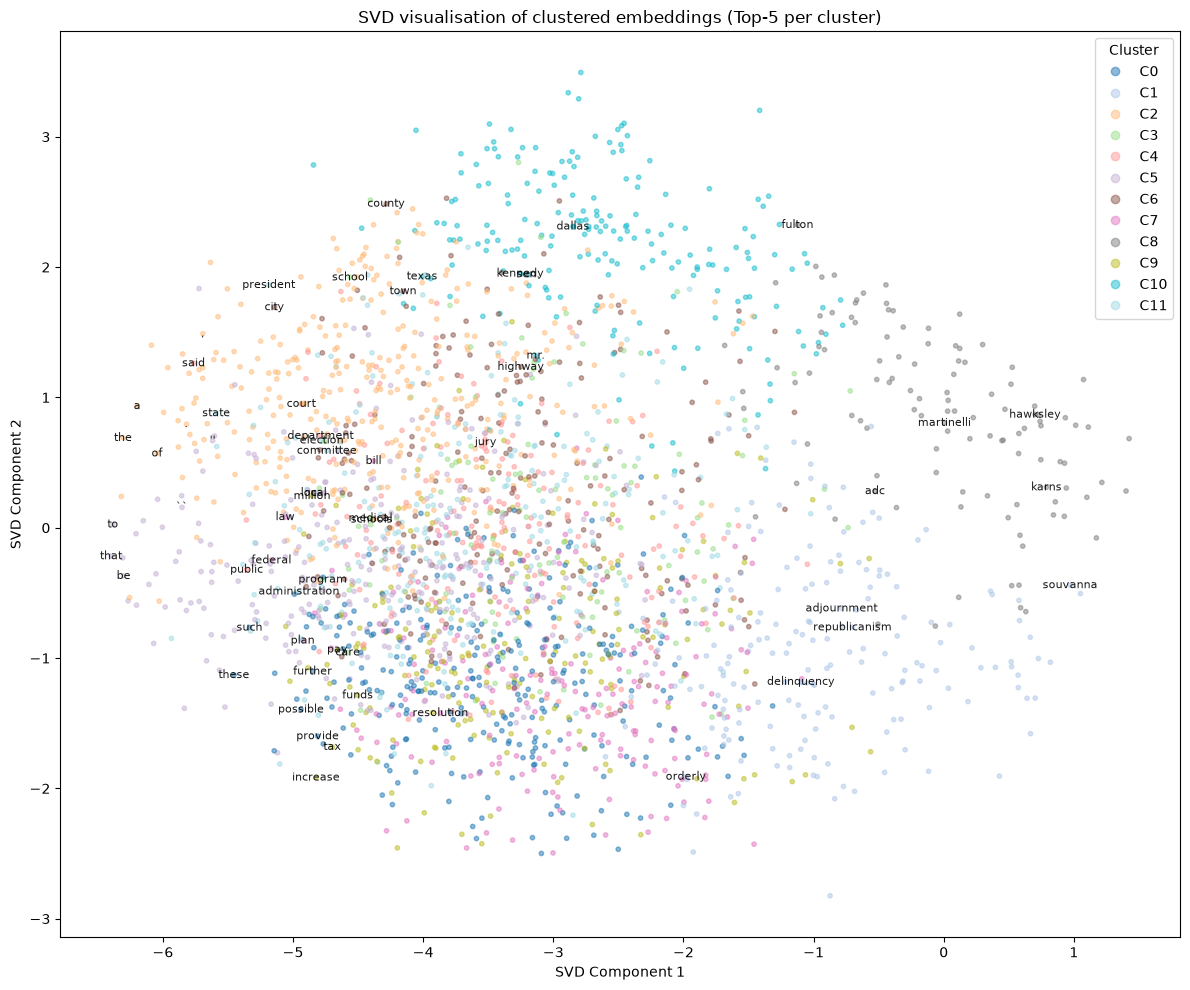

In [44]:
plot_clusters_svd(
    X=X,
    cluster_ids=tagger.labels_,
    vocab=vocab_words,
    input_tokens=input_tokens,
    topn_per_cluster=5,   
    figsize=(12, 10),
    random_state=42
)

### 1.6 Analysis (20%)
Based on the completed code, please conduct experiments to analyse different versions of GloVe (https://nlp.stanford.edu/projects/glove/). You can repeat the above procedures by using different GloVe models and compare their results.

#### 1.6.1 Model 2 - 50 dimensions

Much of this replicated code was written by Copilot but required much correcting and refactoring. Despite being **explicitly** told, it was unable to deduce that the reduced dimension would have to be passed manually. It then began running python scripts to try to work out the shape of the data... so I then took matters into my own hands.


50D embedding statistics
- Total token num: 11711
- In-vocab token num: 11558
- OOV token num: 153 (1.31%)
- In-vocab type num: 2626
- Embedding dimension: 50
 K-Means finished
Inertia: 1241.7421
Iterations: 81
Best init seed: 594336917

50D evaluation metrics
Mutual Information (I): 0.7191
Normalised Mutual Info (NMI): 0.2512
Homogeneity: 0.2451
Completeness: 0.2574
V-measure: 0.2511
Variation of Information: 4.2898

Comparison (100D vs 50D)
Metric                            100D       50D
Mutual Information              0.6769    0.7191
NMI                             0.2378    0.2512
Homogeneity                     0.2307    0.2451
Completeness                    0.2452    0.2574
V-measure                       0.2377    0.2511
Variation of Information        4.3407    4.2898


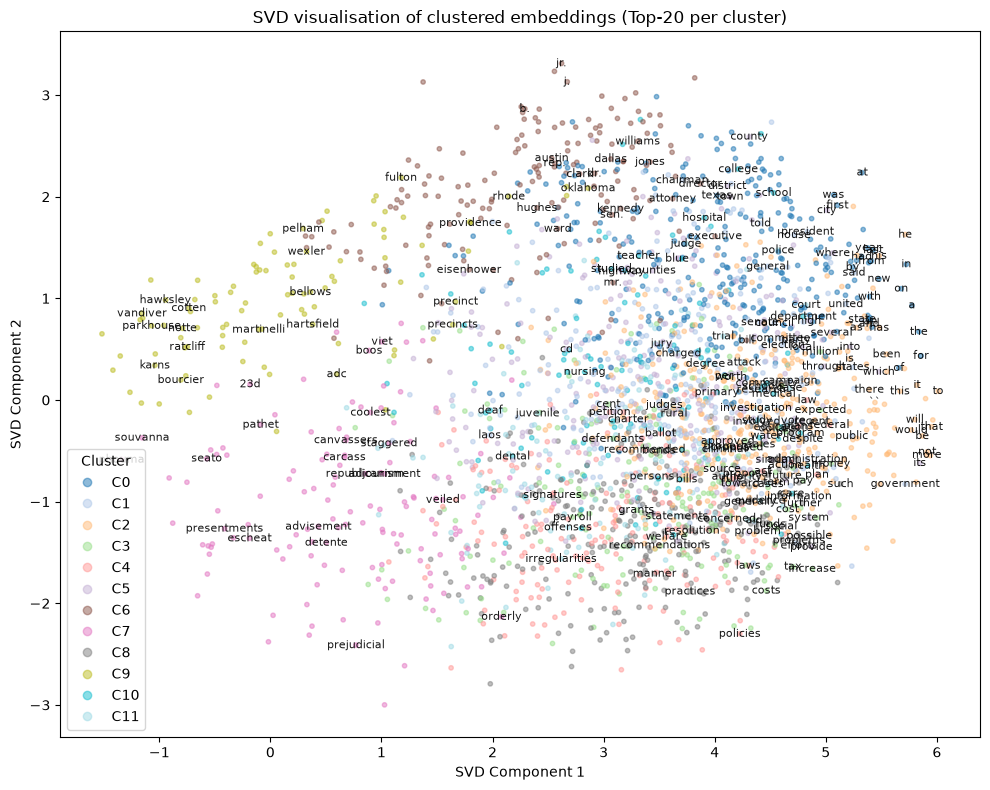

In [45]:
glove_path_50 = "./wiki_giga_2024_50_MFT20_vectors_seed_123_alpha_0.75_eta_0.075_combined.txt"
glove_vectors_50 = load_glove(glove_path_50, dim = 50)

token_embeddings_50, vocab_words_50, X_50, input_tokens_50, gold_tags_50, stats_50 = build_token_embeddings_and_gold_tags(
    tagged_sents=tagged_sents,
    glove_vectors=glove_vectors_50,
    lowercase=True,
)

print("50D embedding statistics")
print(f"- Total token num: {stats_50['total_tokens']}")
print(f"- In-vocab token num: {stats_50['in_vocab_tokens']}")
print(f"- OOV token num: {stats_50['oov_tokens']} ({stats_50['oov_ratio']:.2%})")
print(f"- In-vocab type num: {stats_50['vocab_size_unique_in_glove']}")
print(f"- Embedding dimension: {stats_50['embedding_dim']}")

tagger_50 = KMeansPOSTagger(k=len(unique_upos), n_init=50, max_iter=200, random_state=42)
tagger_50.fit(X_50, vocab_words_50)
word2cluster_50 = tagger_50.word2cluster_

cluster_ids_for_tokens_50 = [word2cluster_50[w] for w in input_tokens_50]
C_50, clusters_50, tags_50 = build_contingency(cluster_ids_for_tokens_50, gold_tags_50)
I_score_50 = mutual_information(C_50)
NMI_score_50 = normalised_mutual_information(C_50)
H_score_50 = homogeneity(C_50)
Cmp_score_50 = completeness(C_50)
V_score_50 = v_measure(C_50)
VI_score_50 = variation_of_information(C_50)

print("\n50D evaluation metrics")
print(f"Mutual Information (I): {I_score_50:.4f}")
print(f"Normalised Mutual Info (NMI): {NMI_score_50:.4f}")
print(f"Homogeneity: {H_score_50:.4f}")
print(f"Completeness: {Cmp_score_50:.4f}")
print(f"V-measure: {V_score_50:.4f}")
print(f"Variation of Information: {VI_score_50:.4f}")

print("\nComparison (100D vs 50D)")
print(f"{'Metric':<28}{'100D':>10}{'50D':>10}")
for metric, score_100, score_50 in [
    ("Mutual Information", I_score, I_score_50),
    ("NMI", NMI_score, NMI_score_50),
    ("Homogeneity", H_score, H_score_50),
    ("Completeness", Cmp_score, Cmp_score_50),
    ("V-measure", V_score, V_score_50),
    ("Variation of Information", VI_score, VI_score_50),
]:
    print(f"{metric:<28}{score_100:>10.4f}{score_50:>10.4f}")

plot_clusters_svd(
    X=X_50,
    cluster_ids=tagger_50.labels_,
    vocab=vocab_words_50,
    input_tokens=input_tokens_50,
    random_state=42,
)


#### 1.6.3 Hypothesis

Within this Brown-corpus part-of-speech (PoS) tagging task, we found that 50D embeddings performed better than the 100D embeddings at clustering. This result may seem counter-intuitive, however extra dimensions may contribute to semantic typing rather than syntactic. In a distance-based method like K-means, extra information may dilute PoS signalling rather than strengthen it. 

Both embedding sets were clustered into 12 groups - each corresponding to a Universal PoS tag from the selected data - using K-means and both were scored against the gold (correct) tags. Both runs had matched coverage and clustering configuration over the Brown sentences and OOV tokens excluded. 

The 50D model scored higher on both measures (NMI - 0.2521 v 0.2378 and V-Measure - 0.2511 v 0.2377) and its Variation of Information was lower (4,2898 vs 4.3407). These are small changes of ~6% or less and the absoulte scores are low. Neither model is able to uncover much of the PoS structure, but observation tells us that 50D was measurably stronger. 

However, agreement across multiple metrics is certainly not unexpected with the same entropy and mutual-information terms being used to calculate them so they tend to follow a trend. A possibly more informative observation that can be made is that homogeneity and completeness both improved by a similar amount (0.0144 and 0.0122 respectively). This suggests that the 50D clusters did not simply fragment better or merge for completeness but that gains were made on both ends. We find that completeness is also greater than homogenity in both models which indicates that tokens with the same tag tend to position similarly.

Looking to the K-means mechanism of Euclidean distance, it seems to be that distance becomes less and less discriminating as dimensionality grows. And ,as mentioned before, if effects of semantics or other than that were encoded in additional dimensions, clusters could be begin converging on these rather than syntactic classes. This is just one plausible explanation for why fewer dimensions could have produced a slight gain - however this remains a hypothesis as no metric directly verifies this. 

A limitation of this comparison is that different seed values may have caused the differences rather than dimensionality. With marginal variations, this certainly could be the case. In addition to this, simply using 500 sentences may poorly represent rarer tags which could incline results to more common clusters. 

The apparent results are consistent with the hypothesis but may not be significant enough to assert it. Further repetitions as well as a larger corpus of sentences would further strengthen these results. 

## 2. Apply Word2Vec to Unsupervised Extractive Summarisation

In this section, we use Word2Vec embeddings to perform unsupervised extractive summarisation.  
The core idea of extractive summarisation is to select the most representative and informative sentences from the original document to form a concise summary without rewriting.


In this task, we use TextRank to summarise CNNDM dataset.

### 2.1 Load Document-Summary Paris from CNNDM
We use the first 100 lines of data for experiments. Please download the test.csv file from the Moodle page. To ensure text quality and consistency, we perform text cleaning before using the data as model inputs.

In [47]:
import pandas as pd
from typing import Tuple

import re
import html

def clean_text(s: str) -> str:
    s = html.unescape(s)
    s = s.replace("\xa0", " ").replace("\u200b", "").replace("\ufeff", "")
    s = s.replace("\n", " ").replace("\r", " ").replace("\t", " ")
    s = s.replace("“", '"').replace("”", '"').replace("’", "'").replace("‘", "'")
    s = s.replace("–", "-").replace("—", "-").replace("…", "...")
    s = re.sub(r"http\S+|www\.\S+", "", s)
    s = re.sub(r"\s+", " ", s)
    s = s.strip().lower()
    return s


def extract_cnndm_test_first_n(
    csv_path: str,
    n: int = 100,
    article_col: str = "article",
    summary_col: str = "highlights",
) -> Tuple[list, list]:
    """
    Extract the first N samples from a CNNDM CSV file,
    clean & lowercase text, and return (inputs, references).
    """
    df = pd.read_csv(csv_path)
    assert article_col in df.columns and summary_col in df.columns, \
        f"Missing required columns: '{article_col}' or '{summary_col}'"

    n = min(n, len(df))
    sub = df.iloc[:n].copy()

    inputs = [clean_text(str(x)) for x in sub[article_col].fillna("")]
    references = [clean_text(str(x)) for x in sub[summary_col].fillna("")]

    return inputs, references

cnndm_path = "./cnndm_test.csv" # Replace path_to_your_file with the path to the cnndm csv file.
docs, summaries = extract_cnndm_test_first_n(cnndm_path, n=100)


### 2.2 Convert Documents into Sentence Embeddings

In this step, we split each document into sentences and convert them into embeddings:
- Use nltk sent_tokenize for sentence segmentation.
- Tokenise each sentence and look up GloVe embeddings.
- Compute the average of token vectors to get a sentence embedding (use zero vector if no tokens found).
- Record each sentence’s document index.

Outputs inclue:
- sentence_embeddings: matrix of all sentence vectors
- sentences: corresponding sentence texts
- doc_index: mapping of each sentence to its document.

In [48]:
import numpy as np
import nltk
from typing import List, Tuple

nltk.download('punkt')

def compute_sentence_embeddings(
    docs: List[str],
    glove_vectors: dict,
) -> Tuple[np.ndarray, List[str], List[int]]:
    """
    Segment documents into sentences and compute sentence embeddings
    by averaging pre-trained GloVe word embeddings.

    Parameters
    ----------
    docs : list[str]
        List of input article texts.
    glove_vectors : dict
        Pre-trained GloVe word embeddings {token: vector}.

    Returns
    -------
    sentence_embeddings : np.ndarray [num_sentences, dim]
        Sentence-level embedding matrix.
    sentences : list[str]
        List of sentences in the same order as embeddings.
    doc_index : list[int]
        Document index for each sentence (e.g., sentence i belongs to docs[doc_index[i]]).
    """
    all_sentences = []
    doc_index = []

    for doc_id, text in enumerate(docs):
        sents = nltk.sent_tokenize(text)
        all_sentences.extend(sents)
        doc_index.extend([doc_id] * len(sents))

    sentence_vecs = []
    for sent in all_sentences:
        tokens = sent.split()  
        vecs = [glove_vectors[w] for w in tokens if w in glove_vectors]
        if len(vecs) == 0:
            sentence_vecs.append(np.zeros(next(iter(glove_vectors.values())).shape))
        else:
            sentence_vecs.append(np.mean(vecs, axis=0))

    sentence_embeddings = np.vstack(sentence_vecs)

    return sentence_embeddings, all_sentences, doc_index


sentence_embeddings, sentences, doc_index = compute_sentence_embeddings(docs, glove_vectors)

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/aalimkalam/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/aalimkalam/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


### 2.3 TextRank for Unsupervised Summarisation. (30%)

Please refer to this paper for the algorithm https://aclanthology.org/W04-3252.pdf.

You can directly call the PageRank algorithm through `nextworkx`: https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html

In [78]:
import numpy as np
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity
from typing import List

class TextRankSummarizer:
    """
    Minimal TextRank implementation for unsupervised extractive summarisation.
    Uses PageRank over a sentence similarity graph.
    """

    def __init__(self, topk: int = 3):
        """
        Parameters
        ----------
        topk : int
            Number of sentences to extract per document.
        """
        self.topk = topk

    # Please complete your code here.
    ### sentence_embeddings: matrix of all sentence vectors
    ### sentences: corresponding sentence texts
    ### doc_index: mapping of each sentence to its document

    # pairwise cosine similarities between sentence vectors
    def similarity_matrix(self, sentence_embeddings):
        return cosine_similarity(sentence_embeddings)

    # weighted sentence graph from similarities
    def build_graph(self, similarity_matrix, sentences):
        graph = nx.Graph()
        ### graph.add_nodes_from((i, {"text": sentence}) for i, sentence in enumerate(sentences))
        graph.add_nodes_from(range(len(sentences)))

        for i in range(len(sentences)):
            for j in range(i+1, len(sentences)):
                weight = similarity_matrix[i,j]
                if weight > 0:
                    graph.add_edge(i, j, weight = weight)
                
        return graph

    # return topk ranked sentences in their original order
    def summarise(self, sentence_embeddings, sentences, doc_index):
        doc_index = np.asarray(doc_index)
        num_docs = int(doc_index.max()) + 1

        summaries = []

        for d in range(num_docs):
            idxs = np.where(doc_index == d)[0]
            if len(idxs) == 0:
                summaries.append("") # realigns for empty docs after cleaning
                continue


            similarities = self.similarity_matrix(sentence_embeddings[idxs])
            graph = self.build_graph(similarities, [sentences[i] for i in idxs])
        
            pagerank = nx.pagerank(graph, weight = "weight")
            
            ranked_sentences = sorted(range(len(idxs)), key = lambda k : pagerank[k], reverse = True)
            topk_sentences = ranked_sentences[:self.topk]
            topk_sentences.sort()

            summaries.append(" ".join(sentences[idxs[k]] for k in topk_sentences))

        return summaries
    

In [79]:
textrank = TextRankSummarizer(topk=3)

system_summaries = textrank.summarise(sentence_embeddings, sentences, doc_index)
print(system_summaries[0])


with increasing numbers of people taking to the skies, some experts are questioning if having such packed out planes is putting passengers at risk. this week, a u.s consumer advisory group set up by the department of transportation said at a public hearing that while the government is happy to set standards for animals flying on planes, it doesn't stipulate a minimum amount of space for humans. but these tests are conducted using planes with 31 inches between each row of seats, a standard which on some airlines has decreased, reported the detroit news.


### 2.4 Evaluation using Rouge

We evaluate the quality of the system-generated summaries (system_summaries) against the gold references (summaries) using ROUGE metrics.
ROUGE (Recall-Oriented Understudy for Gisting Evaluation) is a standard evaluation metric for summarisation, measuring the lexical overlap between system outputs and human-written summaries.

You can install the rouge package by:
```
!pip install rouge-score
```

In [80]:
from rouge_score import rouge_scorer

def evaluate_rouge(system_summaries, gold_summaries):
    """
    Compute average ROUGE-1/2/L F1 scores over the dataset.
    """
    scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)
    scores = {'rouge1': 0, 'rouge2': 0, 'rougeL': 0}
    n = len(system_summaries)

    for sys_sum, gold_sum in zip(system_summaries, gold_summaries):
        s = scorer.score(gold_sum, sys_sum)
        for key in scores:
            scores[key] += s[key].fmeasure

    for key in scores:
        scores[key] /= n
    return scores

rouge_scores = evaluate_rouge(system_summaries, summaries)
print("ROUGE scores:", rouge_scores)


ROUGE scores: {'rouge1': 0.30249543865008216, 'rouge2': 0.097647875962971, 'rougeL': 0.18369091367277648}


### 2.5 Discussion and Analysis (30%)

Please discuss the result compared with other extractive models, such as the Lead-N model (https://arxiv.org/pdf/1908.08345). You may need to perform additional experiments to demonstrate your analysis (please write and excute your code below).

In [ ]:
#### 2.5.1 Analysis

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
doc_index = np.asarray(doc_index)
sentences = np.array(sentences)

def evaluate(preds, refs=summaries):
    scores = [scorer.score(ref, pred) for pred, ref in zip(preds, refs)]
    return [100 * np.mean([x[m].fmeasure for x in scores]) for m in ["rouge1", "rouge2", "rougeL"]]

def lead_k(k):
    return [" ".join(sentences[doc_index == d][:k]) for d in range(len(docs))]

### AI was used for table generation and formatting
rows = []
for k in range(1, 6):
    tr = TextRankSummarizer(topk=k).summarise(sentence_embeddings, sentences, doc_index)
    rows.append([k, *evaluate(lead_k(k)), *evaluate(tr)])

cols = ["k"] + [f"{sys} {m}" for sys in ["Lead", "TextRank"] for m in ["R-1", "R-2", "R-L"]]
print(pd.DataFrame(rows, columns=cols).round(2).to_string(index=False))

 k  Lead R-1  Lead R-2  Lead R-L  TextRank R-1  TextRank R-2  TextRank R-L
 1     29.44     10.42     19.63         25.33          6.98         16.87
 2     38.35     15.82     24.12         29.98          9.32         19.07
 3     39.46     17.11     25.06         30.25          9.76         18.37
 4     37.78     16.76     24.45         29.60         10.15         17.90
 5     36.45     16.69     23.44         28.06          9.96         17.22


#### 2.5.2 Discussion

I compared my GloVe-mean TextRank implementation against the Lead-N baseline on the first 100 CNN/DM test articles using rouge-1, rouge-2 and rouge-L F1. I also invesitgated whether comparison depends on summary length by varying the number of extracted sentences (k) between 1 and 5. 

The primary result at k=3 gives Lead-3 scores R-1/R-2/R-L of 39.46/17.11/25.06 and TextRank had 30.25/9.76/18.37. Lead-3 is substantially higher so TextRank is not able to match up to this baseline; the Lead-3 figures are close to the paper's numbers. 

Lead-N is maximised at k=3 for all three metrics, after which results actually fall. This is likely induced by extra sentences that are not in the reference. TextRank also peaks at k=3 for both R-1 and R-L with R-2 peaking at k=4. I anticipated that the gap would between the models would grow, however we found that the gap between the models is smallest at k=1 where both models are limited by how little text they select. 

Lead-N is difficult to beat due to its factoring in of positioning, an aspect that TextRank does not quantify. News articles such as the data that was used often begin with the most pertinent facts and its is likely that the extracted summary reflects this. TextRank favours sentences with the most common words which may harm extra-specific facts. TextRank also picks sentences independently with no concern for redundancy. This explanation is untested as I did not measure which positions TextRank selects and if any pattern (or lack of) emerges.

This analysis is limited by the corpus of articles used (100) so it alone may not prove significant. However, in conjuction with the substantial difference in results, it is extremely unlikley that the variation can be boiled down to noise. In addition to this, rouge has limited comprehension of paraphrasing and cannot measure the fluency of a summary. A further study on different text-based media types would be interesting to see how the models perform across structurally-distinct corpora. 